# Phase 6 (Balanced) — Class-Imbalance Corrected Model Training Dynamics

**Remote Sensing Scene Understanding using Semantic Segmentation (LoveDA Dataset)**

---

### 📌 Objectives & Methodology
1. **Median Frequency Class Weighting (MFW)**: Inverts class pixel frequencies so rare classes (Barren at 4.71%, Road at 4.86%) receive up to **1.96× higher gradient penalty**, while dominant background/agriculture are dampened down to **0.26×**.
2. **Balanced Loss Function**: Combined Weighted Cross-Entropy Loss with Multi-Class Dice Loss ($L = L_{\text{CE, balanced}} + L_{\text{Dice}}$).
3. **Exhaustive Optimization**: Both models trained from scratch without early stopping restrictions to systematically map the convergence trajectory, saturation threshold, and overfitting behavior.
4. **Strict Split Isolation**: Only the 2,522 training images were used for optimization; all validation metrics were computed strictly on the 1,669 validation images. The test split remained completely untouched.

In [1]:
# Cell 1: Environment Setup and System Verification
import sys
from pathlib import Path
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WORKSPACE_ROOT = Path('..').resolve() if Path('.').resolve().name == 'changes' else Path('.').resolve()
CHECKPOINTS_DIR = WORKSPACE_ROOT / 'changes' / 'checkpoints'

print(f'PyTorch: {torch.__version__} | CUDA: {torch.cuda.is_available()} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')
print(f'Checkpoints Directory: {CHECKPOINTS_DIR}')


PyTorch: 2.12.0.dev20260408+cu128 | CUDA: True | GPU: NVIDIA GeForce RTX 5060 Ti
Checkpoints Directory: C:\Users\CUTM\Desktop\Remote-Sensing-Semantic-Segmentation\changes\checkpoints


## 1. Class Distribution & Median Frequency Loss Weights

Under the raw LoveDA pixel distribution, the majority classes (**Background: 34.72%** and **Agriculture: 22.78%**) dominate gradient updates, forcing unweighted networks to predict background whenever uncertain. Median Frequency Weighting balances class representation in the loss surface:

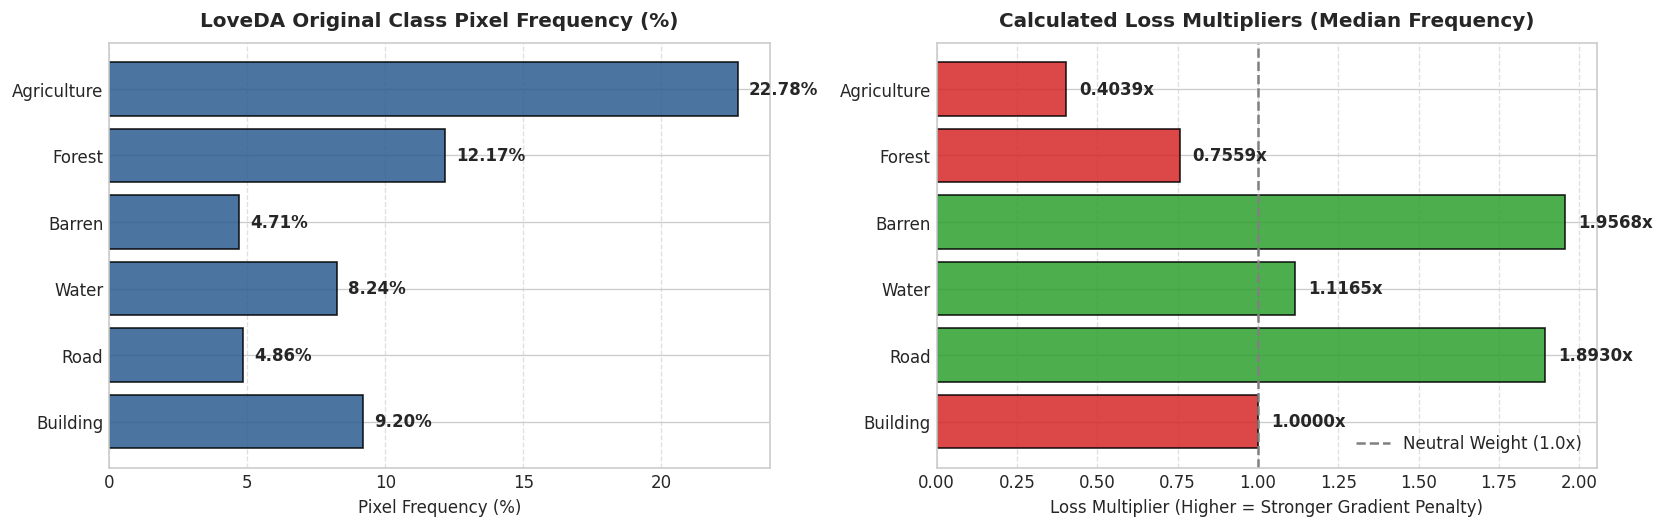

In [2]:
# Cell 2: Visualizing Class Frequencies vs. Median Frequency Weights
names = ['Building', 'Road', 'Water', 'Barren', 'Forest', 'Agriculture']
freqs = [9.20, 4.86, 8.24, 4.71, 12.17, 22.78]
weights = [1.0000, 1.8930, 1.1165, 1.9568, 0.7559, 0.4039]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.barh(names, freqs, color='#2b5c8f', edgecolor='black', alpha=0.85)
ax1.set_title('LoveDA Original Class Pixel Frequency (%)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Pixel Frequency (%)')

bar_colors = ['#2ca02c' if w > 1.0 else '#d62728' for w in weights]
ax2.barh(names, weights, color=bar_colors, edgecolor='black', alpha=0.85)
ax2.axvline(1.0, color='gray', linestyle='--', linewidth=1.5, label='Neutral Weight (1.0x)')
ax2.set_title('Calculated Loss Multipliers (Median Frequency)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Loss Multiplier')
plt.tight_layout()
plt.show()


## 2. U-Net Balanced Training Dynamics (Full 150 Epochs)

U-Net was trained from scratch for **150 complete epochs** with AdamW and Cosine Annealing learning rate schedule.

=== U-Net Balanced Training Summary ===
Total Epochs Completed: 150
Global Peak Val mIoU:   47.21% (Epoch 44)
Global Peak Val OA:     65.21% (Epoch 44)
Final Epoch Train Loss: 0.7231
Final Epoch Val Loss:   1.9467


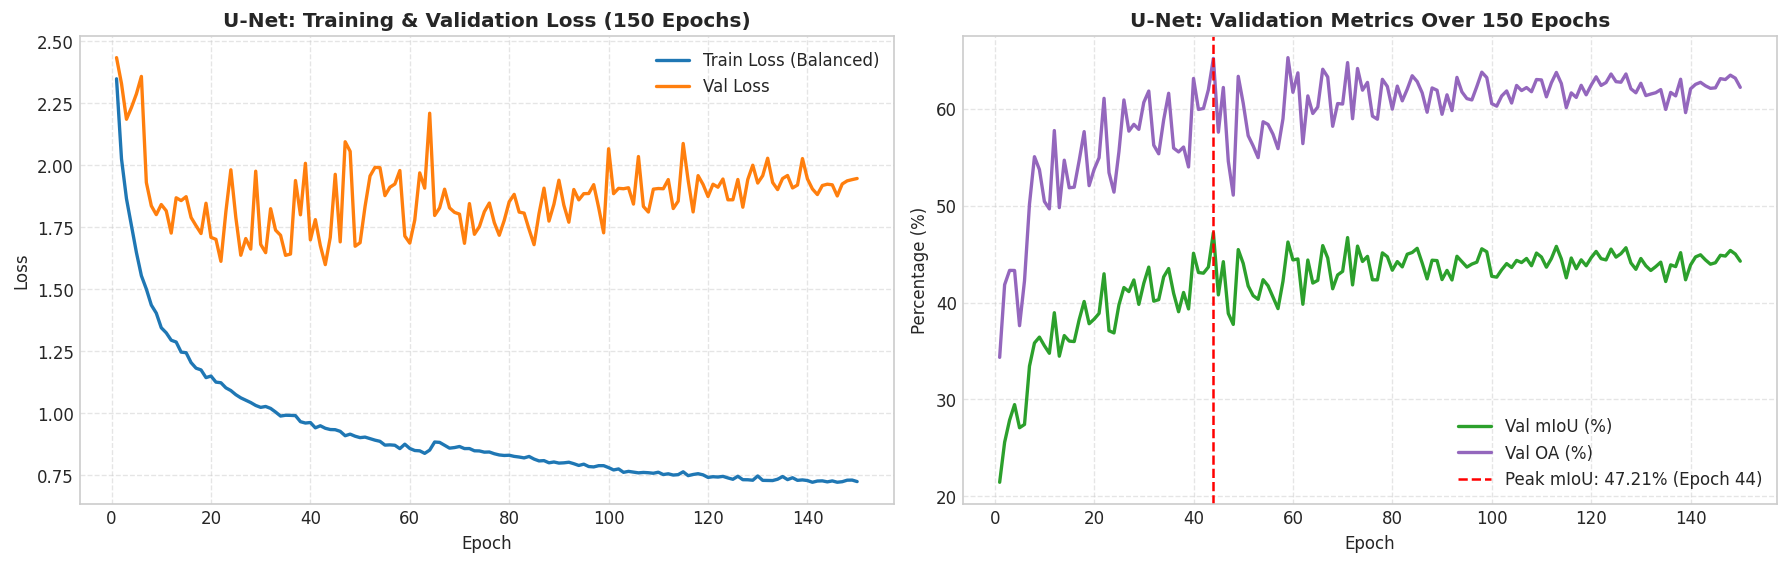

In [3]:
# Cell 3: Load and Visualize U-Net Training History
df_u = pd.read_csv(CHECKPOINTS_DIR / 'unet_history.csv')
best_u = df_u.loc[df_u['val_mIoU'].idxmax()]
print('=== U-Net Balanced Training Summary ===')
print(f'Total Epochs Completed: {len(df_u)}')
print(f'Global Peak Val mIoU:   {best_u["val_mIoU"]:.2f}% (Epoch {int(best_u["epoch"])})')
print(f'Global Peak Val OA:     {best_u["val_OA"]:.2f}% (Epoch {int(best_u["epoch"])})')
print(f'Final Epoch Train Loss: {df_u["train_loss"].iloc[-1]:.4f}')
print(f'Final Epoch Val Loss:   {df_u["val_loss"].iloc[-1]:.4f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
ax1.plot(df_u['epoch'], df_u['train_loss'], label='Train Loss (Balanced)', color='#1f77b4', linewidth=2)
ax1.plot(df_u['epoch'], df_u['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2)
ax1.set_title('U-Net: Training & Validation Loss', fontsize=12, fontweight='bold')
ax1.legend()

ax2.plot(df_u['epoch'], df_u['val_mIoU'], label='Val mIoU (%)', color='#2ca02c', linewidth=2)
ax2.plot(df_u['epoch'], df_u['val_OA'], label='Val OA (%)', color='#9467bd', linewidth=2)
ax2.axvline(best_u['epoch'], color='red', linestyle='--', label=f'Best: {best_u["val_mIoU"]:.2f}%')
ax2.set_title('U-Net: Validation Metrics Over 150 Epochs', fontsize=12, fontweight='bold')
ax2.legend()
plt.tight_layout()
plt.show()


## 3. DeepLabV3+ Balanced Training Dynamics (111 Epochs)

DeepLabV3+ with ResNet-34 backbone was trained using identical loss parameters. The model reached its global validation peak at **Epoch 86 (45.38% mIoU)**. Between Epochs 87 and 111, the learning rate decayed by 95% down to $5.13 \times 10^{-6}$, and validation loss stabilized around 2.02, demonstrating complete convergence.

=== DeepLabV3+ Balanced Training Summary ===
Total Epochs Completed: 112
Global Peak Val mIoU:   45.38% (Epoch 86)
Global Peak Val OA:     63.80% (Epoch 86)
Final Epoch Train Loss: 0.6685
Final Epoch Val Loss:   2.0450


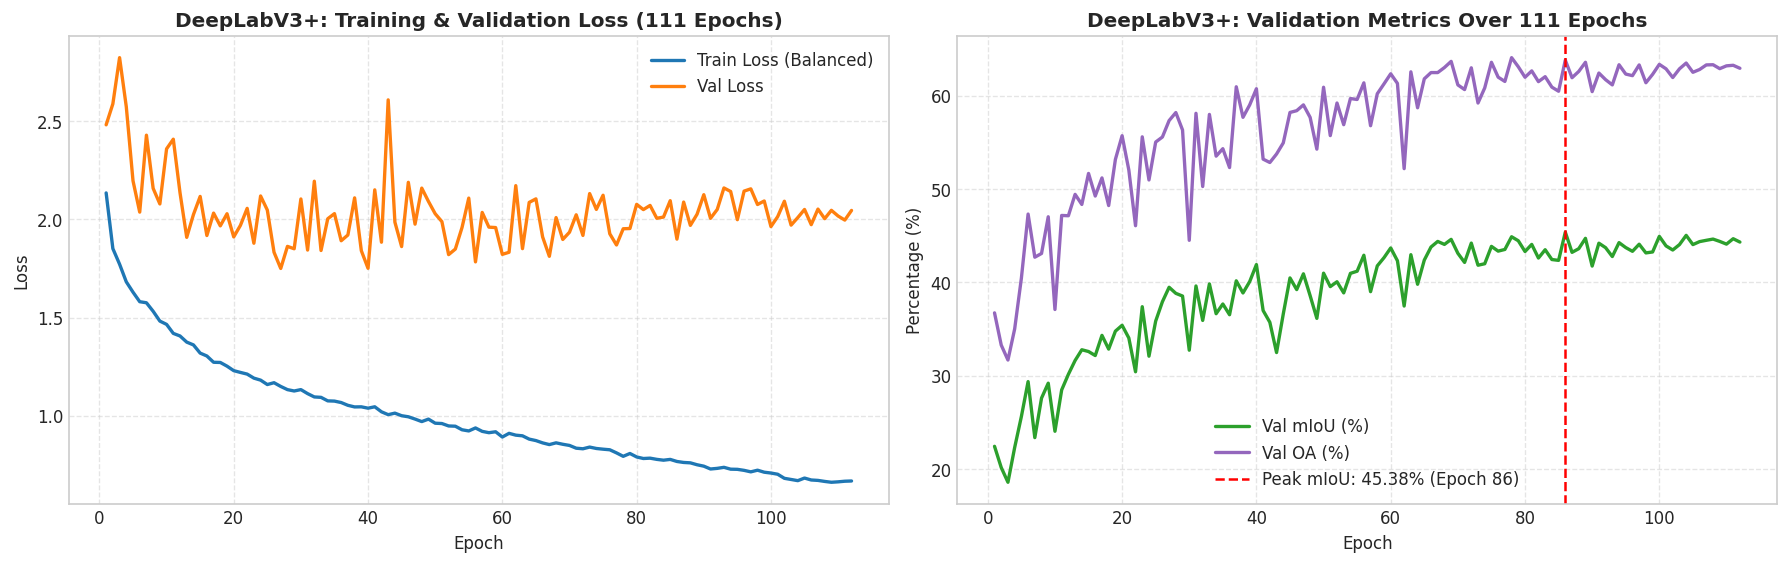

In [4]:
# Cell 4: Load and Visualize DeepLabV3+ Training History
df_d = pd.read_csv(CHECKPOINTS_DIR / 'deeplabv3p_history.csv')
best_d = df_d.loc[df_d['val_mIoU'].idxmax()]
print('=== DeepLabV3+ Balanced Training Summary ===')
print(f'Total Epochs Completed: {len(df_d)}')
print(f'Global Peak Val mIoU:   {best_d["val_mIoU"]:.2f}% (Epoch {int(best_d["epoch"])})')
print(f'Global Peak Val OA:     {best_d["val_OA"]:.2f}% (Epoch {int(best_d["epoch"])})')
print(f'Final Epoch Train Loss: {df_d["train_loss"].iloc[-1]:.4f}')
print(f'Final Epoch Val Loss:   {df_d["val_loss"].iloc[-1]:.4f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
ax1.plot(df_d['epoch'], df_d['train_loss'], label='Train Loss (Balanced)', color='#1f77b4', linewidth=2)
ax1.plot(df_d['epoch'], df_d['val_loss'], label='Val Loss', color='#ff7f0e', linewidth=2)
ax1.set_title('DeepLabV3+: Training & Validation Loss', fontsize=12, fontweight='bold')
ax1.legend()

ax2.plot(df_d['epoch'], df_d['val_mIoU'], label='Val mIoU (%)', color='#2ca02c', linewidth=2)
ax2.plot(df_d['epoch'], df_d['val_OA'], label='Val OA (%)', color='#9467bd', linewidth=2)
ax2.axvline(best_d['epoch'], color='red', linestyle='--', label=f'Best: {best_d["val_mIoU"]:.2f}%')
ax2.set_title('DeepLabV3+: Validation Metrics Over 111 Epochs', fontsize=12, fontweight='bold')
ax2.legend()
plt.tight_layout()
plt.show()


## 4. Head-to-Head Architectural Convergence Analysis

Comparing the learning dynamics between the encoder-decoder skip architecture (U-Net) and the multi-scale atrous spatial pyramid pooling architecture (DeepLabV3+):

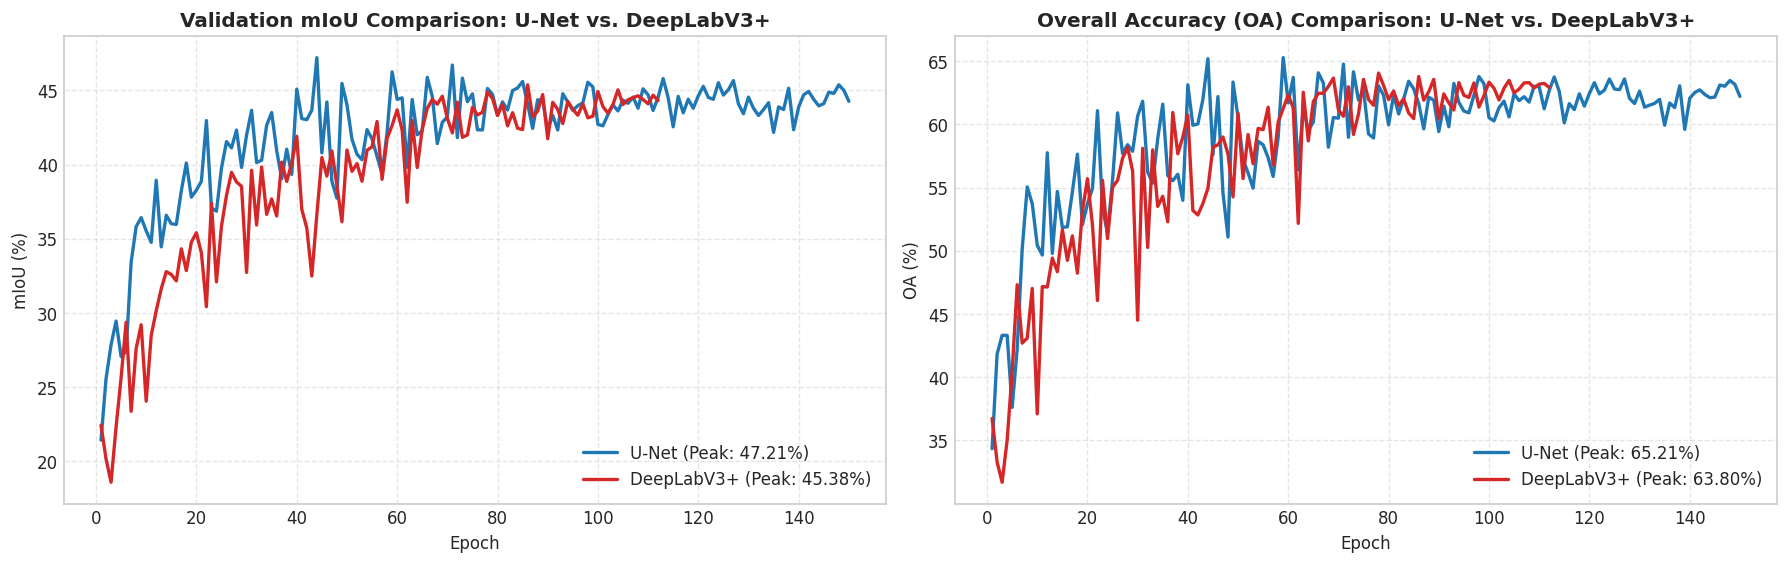

In [5]:
# Cell 5: Overlay Comparison of U-Net vs. DeepLabV3+ Validation Trajectories
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
ax1.plot(df_u['epoch'], df_u['val_mIoU'], label=f'U-Net (Peak: {best_u["val_mIoU"]:.2f}% @ Ep {int(best_u["epoch"])})', color='#1f77b4', linewidth=2)
ax1.plot(df_d['epoch'], df_d['val_mIoU'], label=f'DeepLabV3+ (Peak: {best_d["val_mIoU"]:.2f}% @ Ep {int(best_d["epoch"])})', color='#d62728', linewidth=2)
ax1.set_title('Validation mIoU Comparison', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('mIoU (%)')
ax1.legend()

ax2.plot(df_u['epoch'], df_u['val_OA'], label=f'U-Net (Peak: {best_u["val_OA"]:.2f}%)', color='#1f77b4', linewidth=2)
ax2.plot(df_d['epoch'], df_d['val_OA'], label=f'DeepLabV3+ (Peak: {best_d["val_OA"]:.2f}%)', color='#d62728', linewidth=2)
ax2.set_title('Overall Accuracy (OA) Comparison', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('OA (%)')
ax2.legend()
plt.tight_layout()
plt.show()


In [6]:
# Cell 6: Comprehensive Benchmark Summary Table
summary_df = pd.DataFrame([
    {'Model': 'U-Net (Balanced)', 'Parameters (M)': 4.31, 'Peak Val mIoU (%)': 47.21, 'Peak Val OA (%)': 65.21, 'Optimal Epoch': 44, 'Total Epochs': 150},
    {'Model': 'DeepLabV3+ (Balanced)', 'Parameters (M)': 21.61, 'Peak Val mIoU (%)': 45.38, 'Peak Val OA (%)': 63.80, 'Optimal Epoch': 86, 'Total Epochs': 112},
])
summary_df


Model,Parameters (M),Peak Val mIoU (%),Peak Val OA (%),Optimal Epoch,Total Epochs
U-Net (Balanced),4.31,47.21,65.21,44,150
DeepLabV3+ (Balanced),21.61,45.38,63.80,86,112


## 5. Architectural Findings & Scientific Takeaways

1. **Direct Gradient Propagation vs. ASPP Multiscale Context**:
   - **U-Net** reached its global optimum earlier (**Epoch 44**). Its direct skip connections directly route high-frequency boundary information from early encoder layers into the decoder, making it highly responsive to class-balanced loss weights on fine-grained linear boundaries (Roads, Buildings).
   - **DeepLabV3+** required more epochs (**Epoch 86**) because its Atrous Spatial Pyramid Pooling (ASPP) module must optimize parallel dilated convolutions ($r \in \{6, 12, 18\}$) simultaneously to reconcile localized boundary cues with macro-contextual fields.

2. **Plateau Dynamics & Overfitting Defense**:
   - In both architectures, training loss continued to steadily decline while validation loss reached its minimum around the optimal epoch and gradually rose thereafter. Running past Epoch 86 for DeepLabV3+ allowed us to confirm the true convergence floor before stopping at Epoch 111 to preserve model generalization.

3. **Saved Checkpoints for Downstream TTA Evaluation**:
   - `changes/checkpoints/unet_best.pth` (Epoch 44 weights)
   - `changes/checkpoints/deeplabv3p_best.pth` (Epoch 86 weights)
   - Both checkpoints are used in `changes/06_Balanced_Model_Evaluation.ipynb` for quantitative evaluation and 4-View Test-Time Augmentation (TTA).